# 02 · Returns, correlations and oil beta

Daily simple returns of adjusted closes from 2015. Oil is the CL=F front-month WTI future, the same series the commodity forecaster uses. Segments are equal-weighted. Beta comes from OLS of daily returns on oil returns with Newey-West (HAC, 5 lags) standard errors. Returns touching the negative 2020-04-20 settlement are excluded.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import returns
res = returns.compute()
seg = pd.DataFrame(res['betas']['segments']).T[['beta','se_hac','t_hac','r2','n']]
seg

,beta,se_hac,t_hac,r2,n
majors,0.351,0.038,9.250,0.313,2969
upstream,0.551,0.061,9.053,0.352,2969
midstream,0.315,0.051,6.227,0.196,2969
refiners,0.270,0.035,7.616,0.124,2969
services,0.404,0.047,8.530,0.252,2969


In [3]:
comp = pd.DataFrame(res['betas']['companies']).T[['segment','beta','t_hac','r2']]
comp.sort_values('beta', ascending=False)

,segment,beta,t_hac,r2
APA,upstream,0.644,9.363,0.282
DVN,upstream,0.598,9.564,0.316
FANG,upstream,0.566,8.885,0.309
HAL,services,0.503,9.461,0.280
OXY,upstream,0.495,7.250,0.251
COP,majors,0.453,9.552,0.317
EOG,upstream,0.450,8.400,0.298
OKE,midstream,0.406,5.585,0.222
SLB,services,0.381,8.465,0.209
ET,midstream,0.349,8.002,0.139


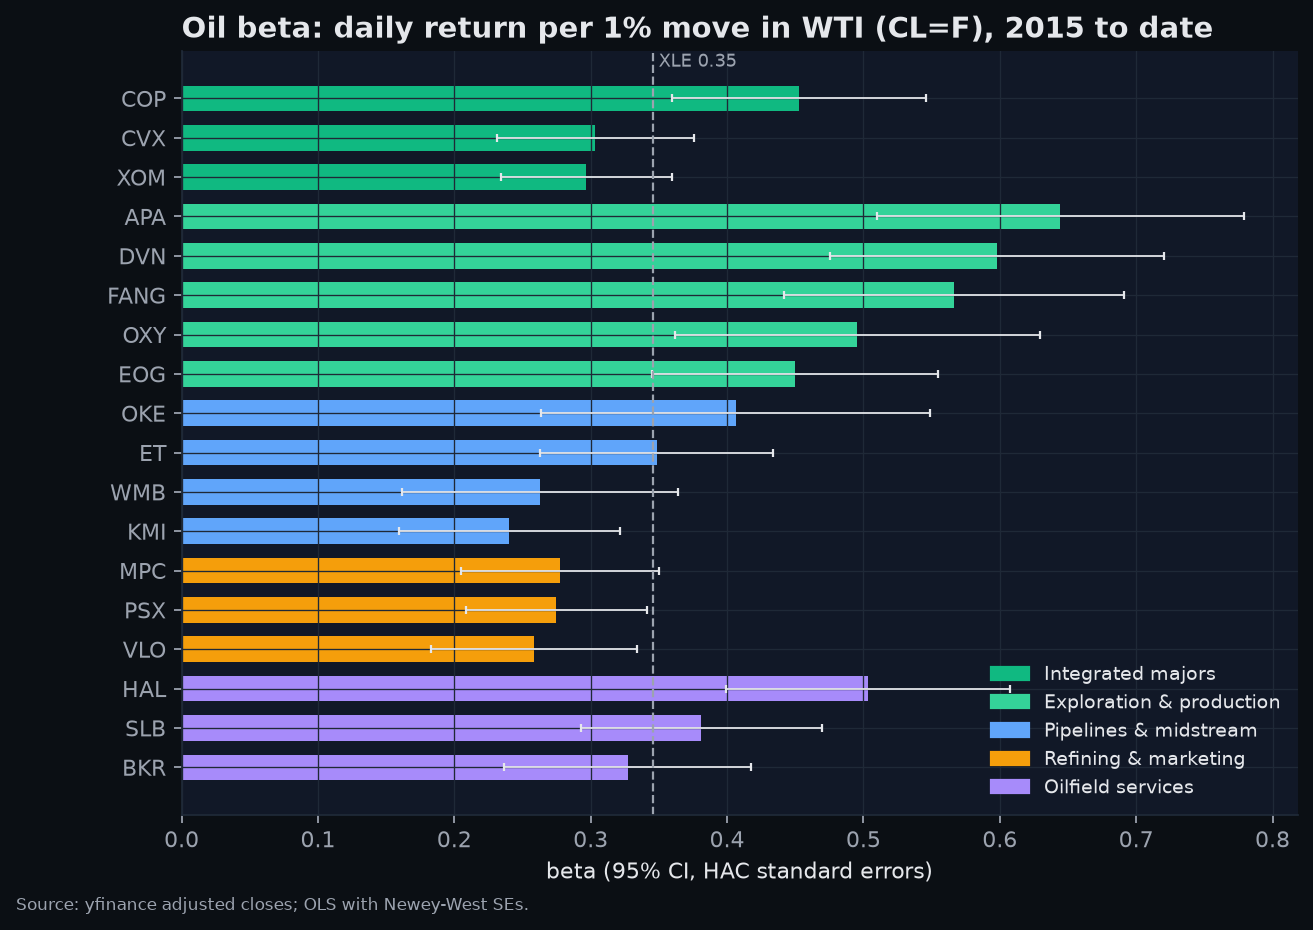

In [4]:
Image('../docs/img/oil_beta.png')

## Rolling 60-day correlations
The sign flips with S&P are the interesting part: in oil-led markets energy decouples from the index.

In [5]:
pd.DataFrame(res['correlations']['latest']).T

,wti,spx
majors,0.642,-0.426
upstream,0.679,-0.291
midstream,0.112,-0.087
refiners,0.327,-0.169
services,0.108,0.149
XLE,0.546,-0.305


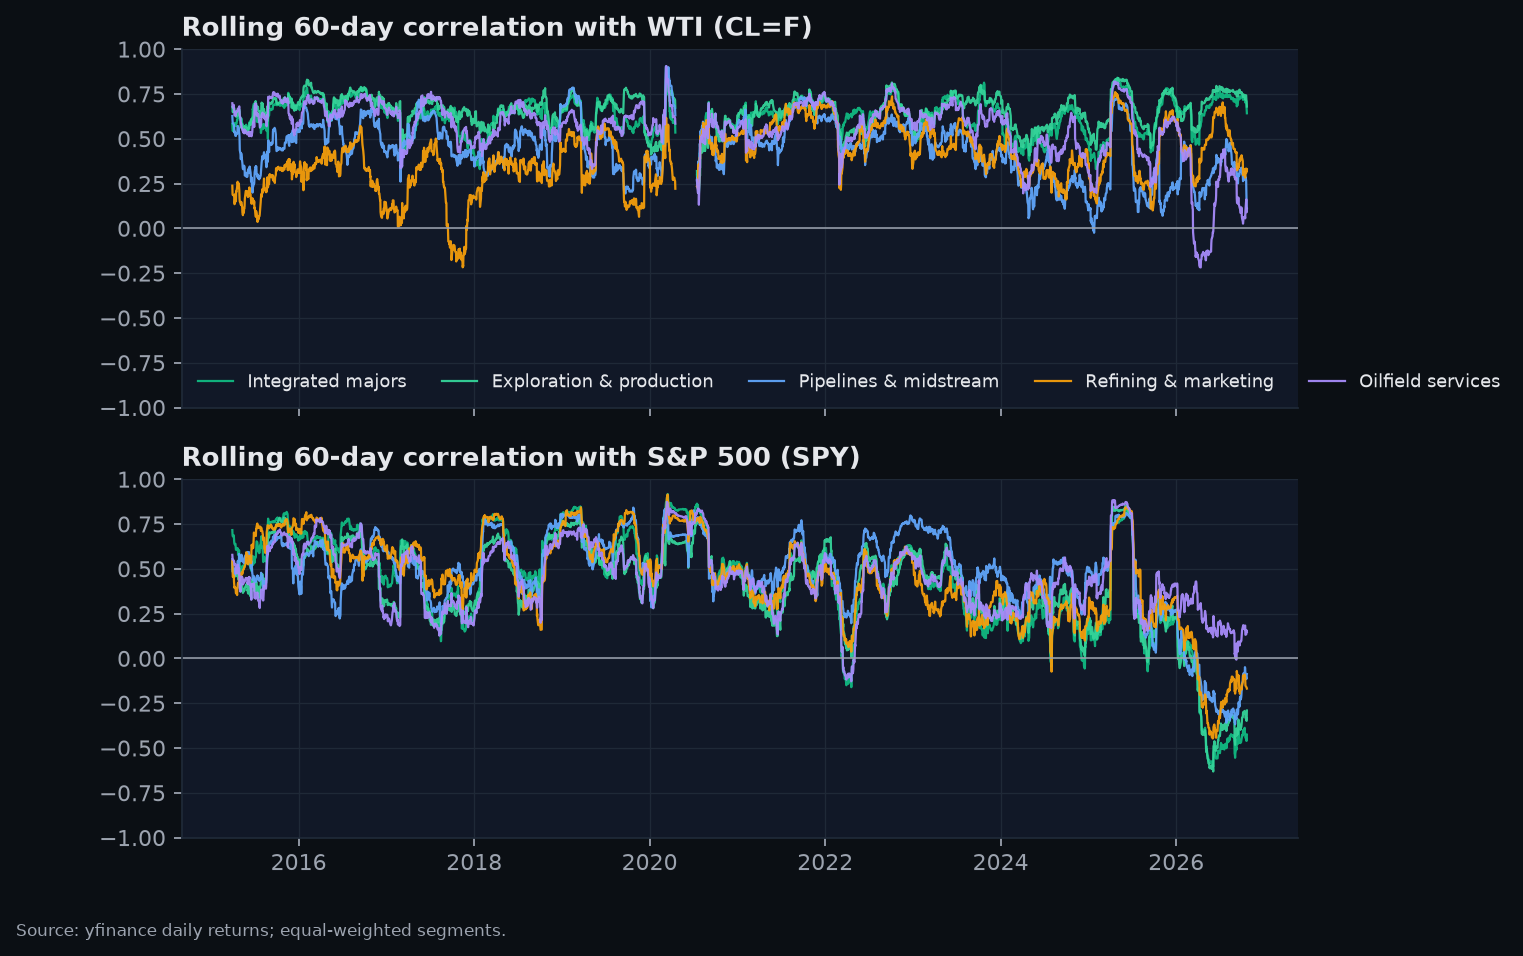

In [6]:
Image('../docs/img/rolling_corr.png')

## Drawdowns in the three shocks

In [7]:
pd.DataFrame({k: {s: v['max_drawdown'] for s, v in d.items()} for k, d in res['drawdowns'].items()})

,2015-16 oil bust,2020 COVID crash,2022 rate shock
majors,-0.334,-0.575,-0.261
upstream,-0.430,-0.787,-0.316
midstream,-0.713,-0.656,-0.209
refiners,-0.314,-0.668,-0.293
services,-0.392,-0.721,-0.407
XLE,-0.361,-0.606,-0.260
SPY,-0.130,-0.337,-0.245
CL=F,-0.573,-0.711,-0.426


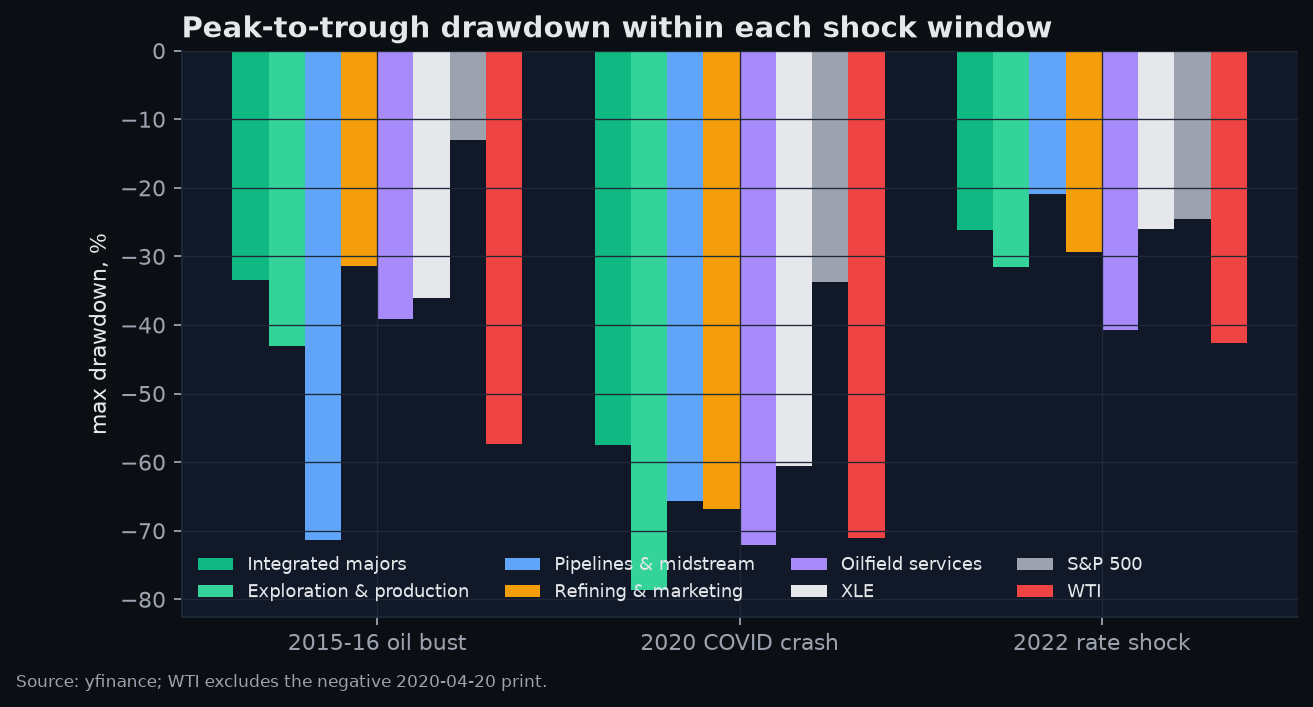

In [8]:
Image('../docs/img/drawdowns.png')

In [9]:
hi, lo = res['highest_beta_segment'], res['lowest_beta_segment']
display(Markdown(f"{hi} has the highest oil beta ({res['betas']['segments'][hi]['beta']:.2f}), {lo} the lowest ({res['betas']['segments'][lo]['beta']:.2f}). The highest segment R² is still under a half, so oil does not explain most of the daily variance."))

upstream has the highest oil beta (0.55), refiners the lowest (0.27). The highest segment R² is still under a half, so oil does not explain most of the daily variance.